# A5 - Uptake and Participation

This notebook uses the enhanced LLM codes to answer RQ2: **whose ideas are taken up and developed in co-constructive exchanges, and how is this participation distributed across students and languages?**

The codes come from the whole-observation run of the enhanced prompt (`analysis/run_enhanced_llm.py`): all 20 of Ms. Gallagher's observations and 9 of Ms. Cooper's, every segment coded. We take these codes as given. A4 showed what that assumption costs: against our adjudicated codes on OBS_26-0498 c–d and OBS_26-0515 a–b, the enhanced prompt matched Whose on 72–82% of turns, and its most common error was reading uptake phrased as a student's own answer as Self. Co-construction is therefore more likely undercounted than overcounted here. This run also differs from the A4 run in three ways: the prompt names no group, the model read the original Spanish without translations, and it received the IM lesson pages instead of our written lesson summary. The A4 agreement numbers are evidence about this run, not a measurement of it.

Sections:

1. Load the LLM codes, the transcript, the metadata, and the GCA scores
2. Build turns and uptake events from the LLM's `turn` and `builds_on` columns
3. Whose ideas are taken up: uptake received by each student, and who builds on whom
4. How participation is distributed: shares and Gini coefficients within each observation
5. Language: whether ideas offered in Spanish, English, or both are taken up at different rates
6. GCA: whether students with more LLM-coded uptake also have higher GCA social impact

Results are reported per classroom, because the two classrooms differ in grade, language use, and teacher, and are never pooled into one number. Run the notebook from the top of the repository. The transcript and metadata are read from `Data/Track A/`, which git ignores. Outputs go to `results/uptake_participation/` and contain codes, counts, and scores only, no transcript text.

## Settings

`LLM_OUTPUTS` lists the LLM files to read. Each file needs one row per transcript line with at least `observation, row, speaker, turn, whose, builds_on, level`; extra columns such as `reason` are ignored. `row` is the segment letter plus the line number, for example `c12`. Keep whole-observation outputs in their own folder: `results/comparison_data/` holds the segment-only A4 files for OBS_26-0498 and OBS_26-0515, and reading both would count those observations twice.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("analysis")
from a4_turns import clean, last_code

LLM_OUTPUTS = sorted(Path("results/llm_enhanced_full").glob("llm_enhanced_*.csv"))
TRANSCRIPT = Path("Data/Track A/all_observations_combined.csv")
METADATA = Path("Data/Track A/observation_metadata.csv")
GCA_SCORES = Path("Data/Track A/gca_outputs/embeddings_w3/gca_student_scores.csv")

OUTPUT_DIR = Path("results") / "uptake_participation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVELOPED_LEVELS = {"medium", "high"}  # co-construction, as defined in A4
CODED_WHOSE = {"self", "other"}
UNNAMED_STUDENT = "Other"  # the transcripts' label for a student who is not named in the metadata
LANGUAGES = ["English", "Spanish", "Both"]

## 1. Load the data

- **LLM codes**: one row per transcript line.
- **Transcript**: only `observation`, `segment`, `#`, `speaker`, and `named_language` are kept; the dialogue is never read into the results. Languages other than English, Spanish, and Both (a few stray codes) are treated as unknown.
- **Metadata**: each observation's teacher (its classroom) and named students, the same lookup the A3 GCA notebook uses.
- **GCA scores**: per-student scores from `A3 - Methods.ipynb` run with multilingual embeddings and a window of three, over whole observations. This file is optional: without it, section 6 is skipped.

**Who counts as a student.** Named students come from the metadata. The speaker labeled "Other" is an unnamed student, except in an observation where the LLM coded every one of their lines N/A, its code for adults: in OBS_25-0259 that speaker reads problems aloud and gives directions, so we treat them as an adult. Everyone else is an adult.

In [2]:
llm = pd.concat([pd.read_csv(path, keep_default_na=False, dtype=str) for path in LLM_OUTPUTS], ignore_index=True)
assert not llm.duplicated(["observation", "row"]).any(), "An observation appears in more than one LLM file."
observations = sorted(llm["observation"].unique())

transcript = pd.read_csv(TRANSCRIPT, usecols=["observation", "segment", "#", "speaker", "named_language"],
                         dtype=str, keep_default_na=False)
transcript = transcript[transcript["observation"].isin(observations)].copy()
transcript["row"] = transcript["segment"] + transcript["#"]
transcript["language"] = transcript["named_language"].where(transcript["named_language"].isin(LANGUAGES), "Unknown")

metadata = pd.read_csv(METADATA, usecols=["obs_index", "teacher_pseudonym", "student_pseudonyms"],
                       dtype=str, keep_default_na=False)
metadata["observation"] = metadata["obs_index"].str.strip().str.replace(r"^OBS-", "OBS_", regex=True)
named_students = {
    observation: set(re.findall(r"'([^']+)'", names))
    for observation, names in zip(metadata["observation"], metadata["student_pseudonyms"])
}
classroom_of = dict(zip(metadata["observation"], metadata["teacher_pseudonym"].str.strip()))
CLASSROOMS = sorted({classroom_of[observation] for observation in observations})

lines = llm.merge(transcript[["observation", "row", "language"]], on=["observation", "row"], how="left")
missing_language = lines["language"].isna().sum()
lines["language"] = lines["language"].fillna("Unknown")
for column in ["whose", "level"]:
    lines[column] = lines[column].map(clean)
lines["classroom"] = lines["observation"].map(classroom_of)

# An unnamed speaker whose lines the LLM coded only N/A is treated as an adult.
unnamed = lines[lines["speaker"] == UNNAMED_STUDENT]
adult_like = {observation for observation, group in unnamed.groupby("observation")
              if (group["whose"] == "n/a").all()}


def role(observation, speaker):
    if speaker in named_students.get(observation, set()):
        return "Student"
    if speaker == UNNAMED_STUDENT and observation not in adult_like:
        return "Unnamed student"
    return "Adult"


lines["role"] = [role(o, s) for o, s in zip(lines["observation"], lines["speaker"])]

print(f"{len(LLM_OUTPUTS)} LLM files, {len(observations)} observations, {len(lines)} lines")
print(f"Lines without a transcript match: {missing_language}")
print(f"'Other' treated as an adult in: {sorted(adult_like)}")
summary = lines.groupby("classroom").agg(observations=("observation", "nunique"), lines=("row", "size"))
summary.join(pd.crosstab(lines["classroom"], lines["whose"].replace("", "blank")))

29 LLM files, 29 observations, 7836 lines
Lines without a transcript match: 0
'Other' treated as an adult in: []


,observations,lines,blank,other,self
classroom,,,,,
Ms. Cooper,9,2606,1961,185,460
Ms. Gallagher,20,5230,3394,571,1265


## 2. Turns and uptake events

**Turns** come from the LLM's own `turn` IDs, because that is how the enhanced prompt grouped lines into one mathematical thought. A turn's Whose is the last Whose on its lines, its Level is the last Level, and its language is the language of its lines: English, Spanish, or Both when its lines mix languages or a line is coded Both. The model also gives turn IDs to lines it codes Unclear, and whole observations include off-task talk, so many turns are Unclear. **Participation is counted over coded turns (Self and Other) only.**

**Uptake events** come from `builds_on`. Every Other turn names the row or rows it builds on, usually as `Speaker row` (`Gregorio a6`, `Miguel c24-c27`, `Allison b8; b9`). The parser finds every row ID in the text and takes the source speaker from the transcript, not from the name the LLM wrote, so a misspelled or missing name cannot misattribute an event. A cited range counts once, at its first row, and a row the responder spoke themselves is not counted. Each event links a **source** (the student whose idea is taken up) to a **responder** (the student building on it), with the responder's Level. An event is **developed** when that Level is Medium or High, the A4 definition of co-construction; otherwise it is **acknowledged** (Low or no Level).

In [3]:
ROW_PATTERN = re.compile(r"\b([a-z])(\d+)(?:\s*[-–]\s*[a-z]?\d+)?\b")


def turn_language(values):
    known = {value for value in values if value != "Unknown"}
    if not known:
        return "Unknown"
    if known == {"English"}:
        return "English"
    if known == {"Spanish"}:
        return "Spanish"
    return "Both"


student_lines = lines[(lines["role"] != "Adult") & (lines["turn"] != "")]
row_speaker = lines.set_index(["observation", "row"])["speaker"]
row_turn = student_lines.set_index(["observation", "row"])["turn"]

turns = (
    student_lines.groupby(["observation", "turn"], sort=False)
    .agg(classroom=("classroom", "first"), rows=("row", " ".join), speaker=("speaker", "last"),
         role=("role", "last"), whose=("whose", last_code), level=("level", last_code),
         language=("language", turn_language),
         builds_on=("builds_on", lambda values: " | ".join(v for v in values if v)))
    .reset_index()
)
turns["coded"] = turns["whose"].isin(CODED_WHOSE)
turns["developed"] = (turns["whose"] == "other") & turns["level"].isin(DEVELOPED_LEVELS)

events, parse_log = [], []
for _, turn in turns[turns["whose"] == "other"].iterrows():
    cited = []
    for match in ROW_PATTERN.finditer(turn["builds_on"]):
        row = match.group(1) + match.group(2)
        if (turn["observation"], row) in row_speaker.index and row not in cited:
            cited.append(row)
    if not cited:
        parse_log.append({"observation": turn["observation"], "turn": turn["turn"],
                          "builds_on": turn["builds_on"], "problem": "no row ID found"})
    for row in cited:
        source = row_speaker[(turn["observation"], row)]
        if source == turn["speaker"]:
            parse_log.append({"observation": turn["observation"], "turn": turn["turn"], "builds_on": turn["builds_on"],
                              "problem": f"row {row} is the responder's own line; not counted"})
            continue
        if source not in turn["builds_on"]:
            parse_log.append({"observation": turn["observation"], "turn": turn["turn"], "builds_on": turn["builds_on"],
                              "problem": f"row {row} is spoken by {source}, who is not named"})
        events.append({
            "observation": turn["observation"],
            "classroom": turn["classroom"],
            "responder_turn": turn["turn"],
            "responder": turn["speaker"],
            "responder_language": turn["language"],
            "source_row": row,
            "source_turn": row_turn.get((turn["observation"], row), ""),
            "source": source,
            "source_role": role(turn["observation"], source),
            "level": turn["level"],
            "developed": turn["developed"],
        })

events = pd.DataFrame(events)
language_by_turn = turns.set_index(["observation", "turn"])["language"]
events["source_language"] = [language_by_turn.get((o, t), "Unknown")
                             for o, t in zip(events["observation"], events["source_turn"])]
parse_log = pd.DataFrame(parse_log, columns=["observation", "turn", "builds_on", "problem"])

turns.drop(columns="builds_on").to_csv(OUTPUT_DIR / "turns.csv", index=False)
events.to_csv(OUTPUT_DIR / "uptake_events.csv", index=False)
parse_log.to_csv(OUTPUT_DIR / "builds_on_parse_log.csv", index=False)

print(f"{len(turns)} student turns, {int(turns['coded'].sum())} coded (Self or Other), "
      f"{int((turns['whose'] == 'other').sum())} Other turns, {len(events)} uptake events")
print(f"Events whose source is an adult: {int((events['source_role'] == 'Adult').sum())}")
parse_log.groupby("problem").size() if len(parse_log) else "No parsing problems."

3014 student turns, 1156 coded (Self or Other), 439 Other turns, 545 uptake events
Events whose source is an adult: 0


problem
no row ID found                                     1
row a81 is the responder's own line; not counted    1
dtype: int64

## 3. Whose ideas are taken up

For each student in each observation (`students.csv`), and summed over each classroom's observations for the figures:

- **Self turns**: ideas the student offered as their own.
- **Uptake received**: events where a peer builds on one of the student's lines, split into developed and acknowledged.
- **Self turns taken up**: the share of the student's Self turns that at least one peer later builds on.

Adults are left out: the codebook's Other means building on a peer's idea, so an event with an adult source is a coding error; the cell above reports how many there are.

In [4]:
peer_events = events[events["source_role"] != "Adult"]
taken_up_turns = set(zip(peer_events["observation"], peer_events["source_turn"]))
turns["taken_up"] = [(o, t) in taken_up_turns for o, t in zip(turns["observation"], turns["turn"])]

coded_turns = turns[turns["coded"]]
students = (
    coded_turns.groupby(["observation", "classroom", "speaker", "role"])
    .agg(coded_turns=("turn", "size"),
         self_turns=("whose", lambda w: int((w == "self").sum())),
         other_turns=("whose", lambda w: int((w == "other").sum())),
         developed_turns=("developed", "sum"))
    .reset_index()
)
received = (
    peer_events.groupby(["observation", "source"])
    .agg(uptake_received=("developed", "size"), developed_received=("developed", "sum"))
    .rename_axis(["observation", "speaker"])
)
self_taken_up = (
    coded_turns[coded_turns["whose"] == "self"].groupby(["observation", "speaker"])["taken_up"].sum()
    .rename("self_turns_taken_up")
)
students = (
    students.set_index(["observation", "speaker"])
    .join(received).join(self_taken_up)
    .fillna({"uptake_received": 0, "developed_received": 0, "self_turns_taken_up": 0})
    .reset_index()
)
for column in ["uptake_received", "developed_received", "self_turns_taken_up", "developed_turns"]:
    students[column] = students[column].astype(int)
students["acknowledged_received"] = students["uptake_received"] - students["developed_received"]

by_student = (
    students.groupby(["classroom", "speaker", "role"])
    .agg(observations=("observation", "nunique"),
         **{column: (column, "sum") for column in
            ["coded_turns", "self_turns", "other_turns", "developed_turns", "uptake_received",
             "developed_received", "acknowledged_received", "self_turns_taken_up"]})
    .reset_index()
)
by_student.to_csv(OUTPUT_DIR / "students_by_classroom.csv", index=False)
by_student

,classroom,speaker,role,observations,coded_turns,self_turns,other_turns,developed_turns,uptake_received,developed_received,acknowledged_received,self_turns_taken_up
0,Ms. Cooper,Adam,Student,4,64,43,21,10,21,13,8,10
1,Ms. Cooper,Carrie,Student,1,25,15,10,7,16,10,6,10
2,Ms. Cooper,Clifton,Student,1,8,7,1,0,7,5,2,5
3,Ms. Cooper,Delores,Student,1,7,7,0,0,6,0,6,4
4,Ms. Cooper,Doris,Student,1,21,10,11,8,10,5,5,3
5,Ms. Cooper,Gerald,Student,1,26,13,13,5,18,9,9,10
6,Ms. Cooper,Isaias,Student,2,36,27,9,5,10,6,4,6
7,Ms. Cooper,Tangela,Student,2,13,5,8,1,5,4,1,1
8,Ms. Cooper,William,Student,5,118,78,40,23,38,19,19,19
9,Ms. Gallagher,Allison,Student,2,63,47,16,6,20,9,11,12


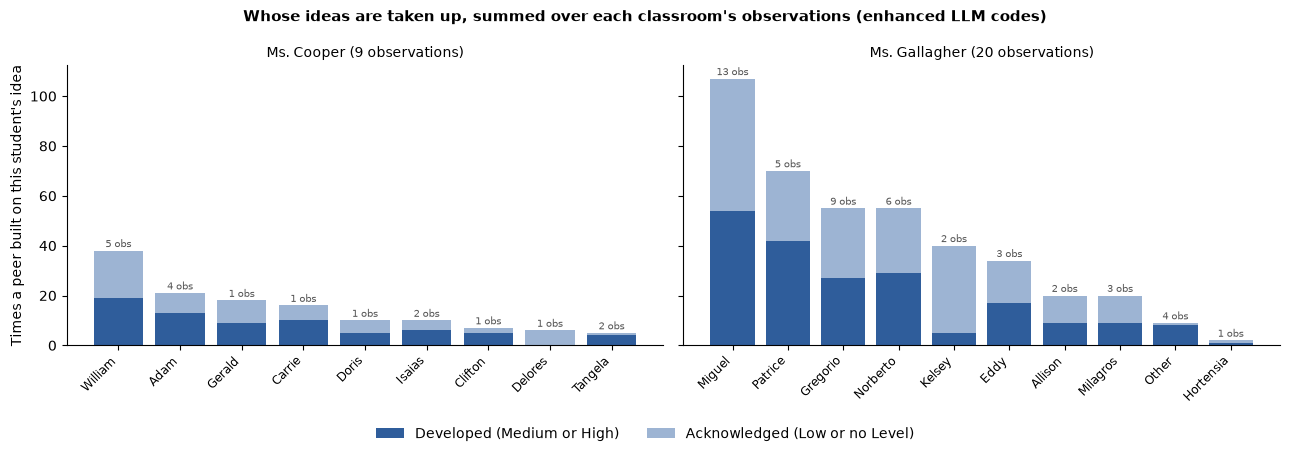

In [5]:
def save_table_image(frame, path, title, font_size=9):
    figure, axis = plt.subplots(figsize=(4, 0.3 * (len(frame) + 2)))
    axis.axis("off")
    shown = axis.table(cellText=frame.astype(str).values, colLabels=frame.columns,
                       cellLoc="left", colLoc="left", loc="upper left")
    shown.auto_set_font_size(False)
    shown.set_fontsize(font_size)
    shown.auto_set_column_width(list(range(frame.shape[1])))
    shown.scale(1, 1.4)
    for (row, column), cell in shown.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_facecolor("#eef2f7")
            cell.set_text_props(weight="bold")
    axis.set_title(title, loc="left", fontsize=11, weight="bold")
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


def fraction(part, whole):
    return f"{part}/{whole} ({part / whole:.0%})" if whole else "0/0"


shown = by_student.sort_values(["classroom", "developed_received"], ascending=[True, False])
uptake_table = pd.DataFrame({
    "Classroom": shown["classroom"],
    "Student": shown["speaker"],
    "Observations": shown["observations"],
    "Self turns": shown["self_turns"],
    "Uptake received": shown["uptake_received"],
    "Developed (Medium+)": shown["developed_received"],
    "Self turns taken up": [fraction(a, b) for a, b in zip(shown["self_turns_taken_up"], shown["self_turns"])],
})
save_table_image(uptake_table, OUTPUT_DIR / "uptake_by_student.png", "Whose ideas are taken up, by student")

COLORS = {"developed": "#2f5d9b", "acknowledged": "#9db4d3"}
figure, axes = plt.subplots(1, len(CLASSROOMS), figsize=(6.5 * len(CLASSROOMS), 4.4), sharey=True, squeeze=False)
for axis, classroom in zip(axes[0], CLASSROOMS):
    shown = by_student[by_student["classroom"] == classroom].sort_values("uptake_received", ascending=False)
    x = np.arange(len(shown))
    axis.bar(x, shown["developed_received"], color=COLORS["developed"], label="Developed (Medium or High)")
    axis.bar(x, shown["acknowledged_received"], bottom=shown["developed_received"],
             color=COLORS["acknowledged"], label="Acknowledged (Low or no Level)")
    for position, (_, student) in zip(x, shown.iterrows()):
        axis.text(position, student["uptake_received"] + 0.5, f"{student['observations']} obs",
                  ha="center", va="bottom", fontsize=7, color="#555555")
    axis.set_xticks(x)
    axis.set_xticklabels(shown["speaker"], rotation=45, ha="right", fontsize=8.5)
    axis.set_title(f"{classroom} ({sum(classroom_of[o] == classroom for o in observations)} observations)",
                   fontsize=10)
    axis.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("Times a peer built on this student's idea")
handles, labels = axes[0][0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.03))
figure.suptitle("Whose ideas are taken up, summed over each classroom's observations (enhanced LLM codes)",
                fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.05, 1, 1))
figure.savefig(OUTPUT_DIR / "uptake_by_student_bars.png", dpi=200, bbox_inches="tight")
plt.show()

### Who builds on whom

One matrix per classroom, summed over its observations. A cell in row A and column B counts the times B built on A's idea; it shows all events with the developed ones in parentheses, and its shade follows the number of events. Students only meet in the groups they were recorded in, so an empty cell can mean the two never worked together. The per-observation counts are saved as `uptake_matrix.csv`.

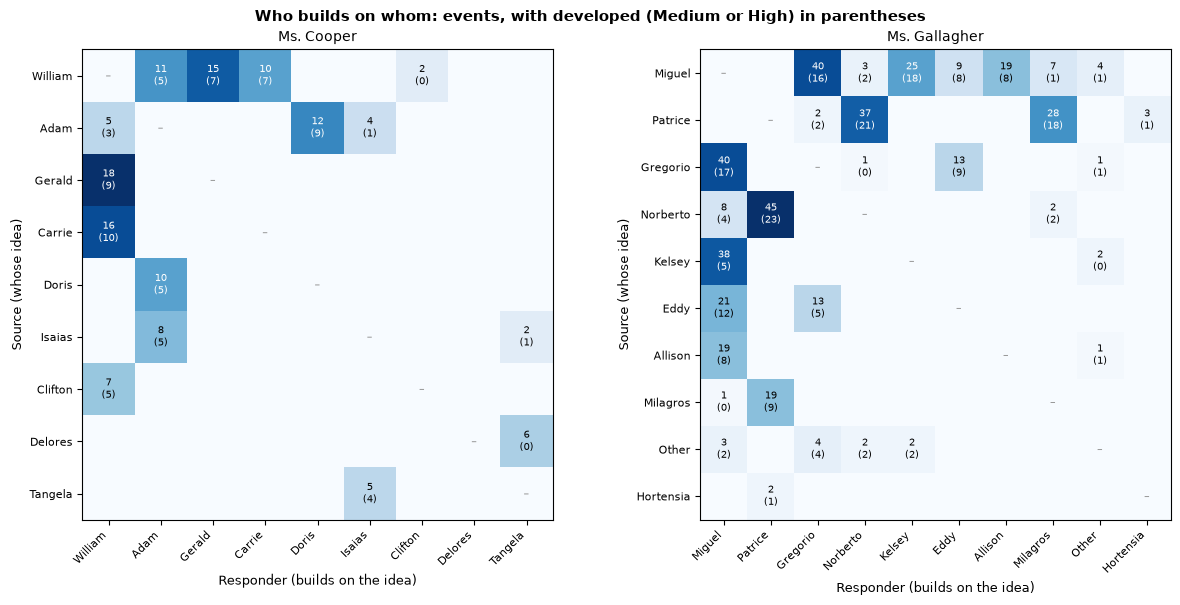

In [6]:
matrix = (
    peer_events.groupby(["observation", "classroom", "source", "responder"])
    .agg(events=("developed", "size"), developed=("developed", "sum"))
    .reset_index()
)
matrix.to_csv(OUTPUT_DIR / "uptake_matrix.csv", index=False)


def plot_matrix(axis, edges, people, title):
    events = edges.pivot_table(index="source", columns="responder", values="events", aggfunc="sum")
    developed = edges.pivot_table(index="source", columns="responder", values="developed", aggfunc="sum")
    events = events.reindex(index=people, columns=people).fillna(0).astype(int)
    developed = developed.reindex(index=people, columns=people).fillna(0).astype(int)
    axis.imshow(events.values, cmap="Blues", vmin=0, vmax=max(events.values.max(), 1))
    for (i, j), value in np.ndenumerate(events.values):
        if i == j:
            axis.text(j, i, "–", ha="center", va="center", fontsize=8, color="#999999")
        elif value:
            axis.text(j, i, f"{value}\n({developed.values[i, j]})", ha="center", va="center", fontsize=7,
                      color="white" if value > events.values.max() / 2 else "black")
    axis.set_xticks(range(len(people)))
    axis.set_xticklabels(people, rotation=45, ha="right", fontsize=8)
    axis.set_yticks(range(len(people)))
    axis.set_yticklabels(people, fontsize=8)
    axis.set_xlabel("Responder (builds on the idea)", fontsize=9)
    axis.set_ylabel("Source (whose idea)", fontsize=9)
    axis.set_title(title, fontsize=10)


figure, axes = plt.subplots(1, len(CLASSROOMS), figsize=(6.2 * len(CLASSROOMS), 6), squeeze=False)
for axis, classroom in zip(axes[0], CLASSROOMS):
    edges = matrix[matrix["classroom"] == classroom]
    people = list(by_student[by_student["classroom"] == classroom]
                  .sort_values("uptake_received", ascending=False)["speaker"])
    people += sorted((set(edges["source"]) | set(edges["responder"])) - set(people))
    plot_matrix(axis, edges, people, classroom)
figure.suptitle("Who builds on whom: events, with developed (Medium or High) in parentheses",
                fontsize=11, weight="bold")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "uptake_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. How participation is distributed

Within each observation, each named student's share of four things: coded turns, Self turns, developed (co-construction) turns, and developed uptake received. The **Gini coefficient** summarizes how unevenly each is spread across the observation's named students: 0 means every student has the same amount, and values near 1 mean one student has almost all of it. With two students, it equals half the difference between their shares. The unnamed student is left out here so every observation compares the students the metadata lists; their turns and uptake are still counted in sections 3 and 5. An observation where a measure is zero for everyone has no Gini for it.

In [7]:
def gini(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0 or values.sum() == 0:
        return np.nan
    return np.abs(values[:, None] - values[None, :]).sum() / (2 * len(values) ** 2 * values.mean())


MEASURES = {"coded_turns": "Coded turns", "self_turns": "Self turns", "developed_turns": "Developed turns",
            "developed_received": "Developed uptake received"}

named = []
for observation in observations:
    rows = students[(students["observation"] == observation) & (students["role"] == "Student")].set_index("speaker")
    rows = rows.reindex(sorted(named_students[observation]))  # students with no coded turns still count as zero
    rows["observation"], rows["classroom"] = observation, classroom_of[observation]
    named.append(rows.fillna({column: 0 for column in MEASURES}).reset_index())
named = pd.concat(named, ignore_index=True)
for column in MEASURES:
    named[f"{column}_share"] = named[column] / named.groupby("observation")[column].transform("sum")

gini_table = pd.DataFrame([
    {"Observation": observation, "Classroom": group["classroom"].iloc[0], "Students": len(group),
     **{label: round(gini(group[column]), 2) for column, label in MEASURES.items()}}
    for observation, group in named.groupby("observation")
])
gini_table.to_csv(OUTPUT_DIR / "gini.csv", index=False)
named.to_csv(OUTPUT_DIR / "students.csv", index=False)
save_table_image(gini_table.fillna(""), OUTPUT_DIR / "gini.png", "Gini coefficient across each observation's named students (0 = equal)")
gini_table.groupby("Classroom")[list(MEASURES.values())].median().round(2)

,Coded turns,Self turns,Developed turns,Developed uptake received
Classroom,,,,
Ms. Cooper,0.06,0.12,0.24,0.22
Ms. Gallagher,0.07,0.16,0.17,0.17


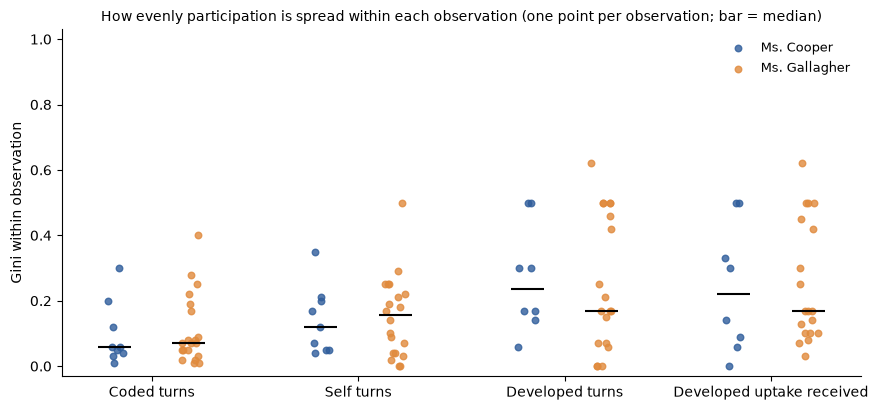

In [8]:
CLASSROOM_COLORS = dict(zip(CLASSROOMS, ["#2f5d9b", "#e08a3c", "#7a9a5b", "#8c6bb1"]))
rng = np.random.default_rng(435)

figure, axis = plt.subplots(figsize=(9, 4.2))
offsets = np.linspace(-0.18, 0.18, len(CLASSROOMS))
for offset, classroom in zip(offsets, CLASSROOMS):
    rows = gini_table[gini_table["Classroom"] == classroom]
    for i, label in enumerate(MEASURES.values()):
        values = rows[label].dropna()
        x = i + offset + rng.uniform(-0.05, 0.05, len(values))
        axis.scatter(x, values, s=22, color=CLASSROOM_COLORS[classroom], alpha=0.8,
                     label=classroom if i == 0 else None, zorder=3)
        if len(values):
            axis.hlines(values.median(), i + offset - 0.08, i + offset + 0.08, color="black", linewidth=1.5, zorder=4)
axis.set_xticks(range(len(MEASURES)))
axis.set_xticklabels(MEASURES.values())
axis.set_ylim(-0.03, 1.03)
axis.set_ylabel("Gini within observation")
axis.legend(frameon=False, fontsize=9)
axis.spines[["top", "right"]].set_visible(False)
axis.set_title("How evenly participation is spread within each observation (one point per observation; bar = median)",
               fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "participation_gini.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Language

Do ideas offered in Spanish, English, or both get taken up at different rates? For each classroom and language, among students' **Self turns** (ideas offered as their own), the share that a peer later builds on, and the share that a peer develops (an uptake event at Medium or High). The second table crosses the language of the source idea with the language of the response, to show whether uptake stays within a language or crosses between them. Turns whose language is unknown are left out of both.

In [9]:
developed_sources = set(zip(peer_events.loc[peer_events["developed"], "observation"],
                            peer_events.loc[peer_events["developed"], "source_turn"]))
self_turns = coded_turns[(coded_turns["whose"] == "self") & (coded_turns["language"] != "Unknown")].copy()
self_turns["developed_by_peer"] = [(o, t) in developed_sources
                                   for o, t in zip(self_turns["observation"], self_turns["turn"])]

language_rows = []
for (classroom, language), group in self_turns.groupby(["classroom", "language"]):
    language_rows.append({"Classroom": classroom, "Language": language, "Self turns": len(group),
                          "Taken up": fraction(int(group["taken_up"].sum()), len(group)),
                          "Developed by a peer": fraction(int(group["developed_by_peer"].sum()), len(group)),
                          "taken_up_rate": group["taken_up"].mean(),
                          "developed_rate": group["developed_by_peer"].mean()})
language_summary = pd.DataFrame(language_rows)
language_summary.to_csv(OUTPUT_DIR / "language_uptake.csv", index=False)
save_table_image(language_summary.drop(columns=["taken_up_rate", "developed_rate"]),
                 OUTPUT_DIR / "language_uptake.png", "Uptake of Self turns by language of the turn")

language_pairs = pd.crosstab(
    [peer_events["classroom"], peer_events["source_language"]], peer_events["responder_language"],
).reindex(columns=LANGUAGES + ["Unknown"], fill_value=0)
language_pairs.to_csv(OUTPUT_DIR / "language_pairs.csv")
display(language_summary.drop(columns=["taken_up_rate", "developed_rate"]))
language_pairs

,Classroom,Language,Self turns,Taken up,Developed by a peer
0,Ms. Cooper,Both,3,0/3 (0%),0/3 (0%)
1,Ms. Cooper,English,192,64/192 (33%),40/192 (21%)
2,Ms. Cooper,Spanish,9,4/9 (44%),1/9 (11%)
3,Ms. Gallagher,Both,19,10/19 (53%),5/19 (26%)
4,Ms. Gallagher,English,460,159/460 (35%),87/460 (19%)
5,Ms. Gallagher,Spanish,33,9/33 (27%),4/33 (12%)


responder_language             English  Spanish  Both  Unknown
classroom     source_language                                 
Ms. Cooper    English              115        0     3        1
              Spanish                1        7     0        0
              Unknown                4        0     0        0
Ms. Gallagher Both                   3       14     6        1
              English              339        4     9        2
              Spanish                2       19     6        0
              Unknown                8        1     0        0

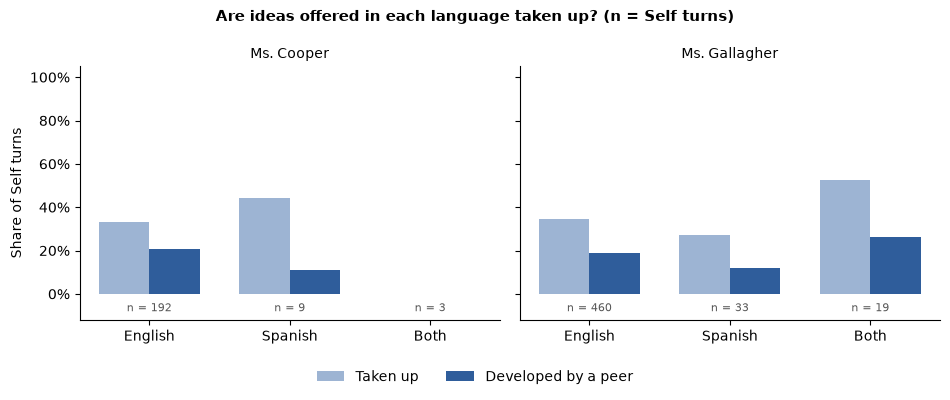

In [10]:
figure, axes = plt.subplots(1, len(CLASSROOMS), figsize=(4.8 * len(CLASSROOMS), 3.8), sharey=True, squeeze=False)
width = 0.36
for axis, classroom in zip(axes[0], CLASSROOMS):
    shown = language_summary[language_summary["Classroom"] == classroom].set_index("Language").reindex(LANGUAGES)
    x = np.arange(len(LANGUAGES))
    axis.bar(x - width / 2, shown["taken_up_rate"].fillna(0), width, color=COLORS["acknowledged"], label="Taken up")
    axis.bar(x + width / 2, shown["developed_rate"].fillna(0), width, color=COLORS["developed"], label="Developed by a peer")
    for position, language in zip(x, LANGUAGES):
        n = shown.loc[language, "Self turns"]
        axis.text(position, -0.08, "n = 0" if pd.isna(n) else f"n = {int(n)}", ha="center", fontsize=8, color="#555555")
    axis.set_xticks(x)
    axis.set_xticklabels(LANGUAGES)
    axis.set_ylim(-0.12, 1.05)
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}" if value >= 0 else ""))
    axis.set_title(classroom, fontsize=10)
    axis.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("Share of Self turns")
handles, labels = axes[0][0].get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
figure.suptitle("Are ideas offered in each language taken up? (n = Self turns)", fontsize=11, weight="bold")
figure.tight_layout(rect=(0, 0.06, 1, 1))
figure.savefig(OUTPUT_DIR / "language_uptake_bars.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. LLM-coded uptake and GCA

Does GCA's semantic-similarity signal line up with the uptake the LLM codes? Both now cover whole observations. Each point is one named student in one observation:

- **Social impact** (how similar peers' next few contributions are to this student's) against **uptake received per Self turn**, both about whether a student's ideas are taken up.
- **Responsivity** (how similar this student's contributions are to peers' previous ones) against the **share of the student's coded turns that are Other**, both about whether a student builds on others.

We report Spearman's rank correlation overall and for each classroom, with the number of points. GCA percentiles are not needed here because both measures are compared within the same set of students.

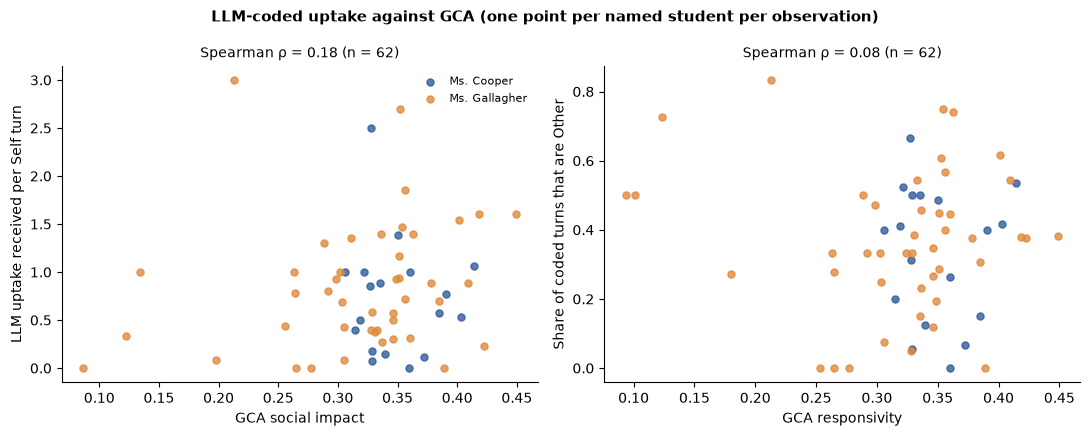

,GCA measure,LLM measure,Scope,Points,Spearman rho
0,GCA social impact,LLM uptake received per Self turn,All,62,0.18
1,GCA social impact,LLM uptake received per Self turn,Ms. Cooper,18,-0.03
2,GCA social impact,LLM uptake received per Self turn,Ms. Gallagher,44,0.27
3,GCA responsivity,Share of coded turns that are Other,All,62,0.08
4,GCA responsivity,Share of coded turns that are Other,Ms. Cooper,18,-0.09
5,GCA responsivity,Share of coded turns that are Other,Ms. Gallagher,44,0.16


In [11]:
if not GCA_SCORES.exists():
    print(f"{GCA_SCORES} not found: run 'A3 - Methods.ipynb' with REPRESENTATION = 'embeddings' first.")
else:
    gca = pd.read_csv(GCA_SCORES)[["observation", "speaker", "social_impact", "overall_responsivity"]]
    compared = named.merge(gca, on=["observation", "speaker"], how="inner")
    compared["uptake_per_self_turn"] = compared["uptake_received"] / compared["self_turns"].replace(0, np.nan)
    compared["other_share"] = compared["other_turns"] / compared["coded_turns"].replace(0, np.nan)
    compared.to_csv(OUTPUT_DIR / "gca_comparison.csv", index=False)

    PAIRS = [("social_impact", "uptake_per_self_turn", "GCA social impact", "LLM uptake received per Self turn"),
             ("overall_responsivity", "other_share", "GCA responsivity", "Share of coded turns that are Other")]
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    correlations = []
    for axis, (x_column, y_column, x_label, y_label) in zip(axes, PAIRS):
        shown = compared.dropna(subset=[x_column, y_column])
        for classroom in CLASSROOMS:
            rows = shown[shown["classroom"] == classroom]
            axis.scatter(rows[x_column], rows[y_column], s=26, alpha=0.8, color=CLASSROOM_COLORS[classroom],
                         label=classroom, zorder=3)
        for scope, rows in [("All", shown)] + [(c, shown[shown["classroom"] == c]) for c in CLASSROOMS]:
            rho = rows[x_column].corr(rows[y_column], method="spearman") if len(rows) > 2 else np.nan
            correlations.append({"GCA measure": x_label, "LLM measure": y_label, "Scope": scope, "Points": len(rows),
                                 "Spearman rho": "" if pd.isna(rho) else round(rho, 2)})
        overall = [c for c in correlations if c["GCA measure"] == x_label and c["Scope"] == "All"][0]
        axis.set_title(f"Spearman ρ = {overall['Spearman rho']} (n = {overall['Points']})", fontsize=10)
        axis.set_xlabel(x_label)
        axis.set_ylabel(y_label)
        axis.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)
    figure.suptitle("LLM-coded uptake against GCA (one point per named student per observation)",
                    fontsize=11, weight="bold")
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / "gca_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()

    correlations = pd.DataFrame(correlations)
    correlations.to_csv(OUTPUT_DIR / "gca_correlations.csv", index=False)
    save_table_image(correlations, OUTPUT_DIR / "gca_correlations.png", "Spearman correlations, LLM-coded uptake vs. GCA")
    display(correlations)

## 7. Findings for the paper

Three descriptive findings for RQ2. This section counts each response **once per student it builds on**: a response that cites several of one peer's rows (for example, "I agree" citing ten of Kelsey's lines) counts as one event, not ten. A student's **ideas offered** are their Self turns, and **developed uptake** is a peer response coded Medium or High that builds on one of those ideas. Only students named in the metadata are counted, so the unnamed student labeled "Other" is left out of this section.

In [12]:
responses = peer_events[peer_events["source_role"] == "Student"].drop_duplicates(["observation", "responder_turn", "source"])
student_turns = turns[turns["role"] == "Student"]
ideas_offered = student_turns[student_turns["whose"] == "self"].groupby(["observation", "speaker"]).size().rename("ideas")
developed_received = (responses[responses["developed"]].groupby(["observation", "source"]).size()
                      .rename_axis(["observation", "speaker"]).rename("developed"))
group_members = student_turns.groupby("observation")["speaker"].unique()
classroom_of = turns.drop_duplicates("observation").set_index("observation")["classroom"]

uptake = pd.concat([ideas_offered, developed_received], axis=1).fillna(0).reset_index()
uptake["classroom"] = uptake["observation"].map(classroom_of)
uptake["partners"] = [", ".join(sorted(set(group_members[o]) - {s})) for o, s in zip(uptake["observation"], uptake["speaker"])]
uptake["developed_per_idea"] = uptake["developed"] / uptake["ideas"].replace(0, np.nan)
uptake.to_csv(OUTPUT_DIR / "findings_uptake_by_student.csv", index=False)
print(f"{len(peer_events)} events before counting each response once, {len(responses)} after; {int(responses['developed'].sum())} developed")

545 events before counting each response once, 428 after; 200 developed


### Finding 1: Uptake depends more on the pairing than on the student

Each row is a student who appears in at least three observations with at least five ideas offered; each dot is one observation, and the lowest and highest are labeled with the student's partner. If uptake were a stable trait of a student, each row's dots would sit close together.

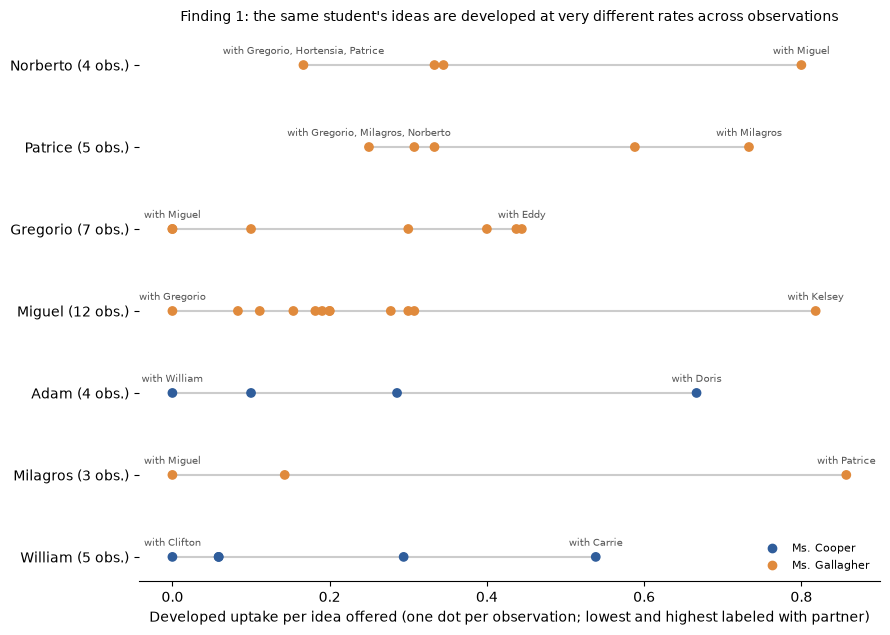

          count   min  median   max   std
speaker                                  
William       5  0.00    0.06  0.54  0.23
Milagros      3  0.00    0.14  0.86  0.46
Adam          4  0.00    0.19  0.67  0.29
Miguel       12  0.00    0.20  0.82  0.20
Gregorio      7  0.00    0.30  0.44  0.20
Patrice       5  0.25    0.33  0.73  0.21
Norberto      4  0.17    0.34  0.80  0.27
Typical spread within a student (mean SD): 0.27; spread between students' averages (SD): 0.10


In [13]:
MIN_IDEAS, MIN_OBSERVATIONS = 5, 3
repeated = uptake[uptake["ideas"] >= MIN_IDEAS].groupby("speaker").filter(lambda g: len(g) >= MIN_OBSERVATIONS)
order = repeated.groupby("speaker")["developed_per_idea"].median().sort_values().index

figure, axis = plt.subplots(figsize=(9, 0.75 * len(order) + 1.2))
for y, student in enumerate(order):
    rows = repeated[repeated["speaker"] == student]
    axis.hlines(y, rows["developed_per_idea"].min(), rows["developed_per_idea"].max(), color="#cccccc", zorder=1)
    axis.scatter(rows["developed_per_idea"], [y] * len(rows), s=36, zorder=3,
                 color=[CLASSROOM_COLORS[c] for c in rows["classroom"]])
    for _, row in rows.loc[[rows["developed_per_idea"].idxmin(), rows["developed_per_idea"].idxmax()]].iterrows():
        axis.annotate(f"with {row['partners']}", (row["developed_per_idea"], y), textcoords="offset points",
                      xytext=(0, 8), ha="center", fontsize=7, color="#555555")
axis.set_yticks(range(len(order)))
axis.set_yticklabels([f"{s} ({(repeated['speaker'] == s).sum()} obs.)" for s in order])
axis.set_xlabel("Developed uptake per idea offered (one dot per observation; lowest and highest labeled with partner)")
axis.spines[["top", "right", "left"]].set_visible(False)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=CLASSROOM_COLORS[c], label=c) for c in CLASSROOMS]
axis.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
axis.set_title("Finding 1: the same student's ideas are developed at very different rates across observations", fontsize=10, pad=14)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "finding1_uptake_by_partner.png", dpi=200, bbox_inches="tight")
plt.show()

spread = repeated.groupby("speaker")["developed_per_idea"].agg(["count", "min", "median", "max", "std"]).round(2)
print(spread.sort_values("median").to_string())
print(f"Typical spread within a student (mean SD): {spread['std'].mean():.2f}; "
      f"spread between students' averages (SD): {repeated.groupby('speaker')['developed_per_idea'].mean().std():.2f}")

**What we see.** Uptake depends more on the pairing than on the student. Among the seven students who appear in at least three observations, a student's own rate varies about three times as much across observations (mean standard deviation 0.27) as the students' averages differ from one another (0.10). Miguel, who appears in 12 observations, ranges from no developed uptake with Gregorio (OBS_26-0600) to 0.82 developed responses per idea with Kelsey (OBS_25-0342). Milagros ranges from 0 with Miguel to 0.86 with Patrice, and Adam from 0 with William to 0.67 with Doris. We therefore read uptake as something produced by a pair working on a particular task, not as a stable trait of a student.

### Finding 2: "Building on" a peer can mean different roles

For each pair of students in the same observation, how each one responds to the other: responses that only acknowledge or agree (Low or no Level) and responses that develop the idea (Medium or High). Directions with at least eight responses are shown.

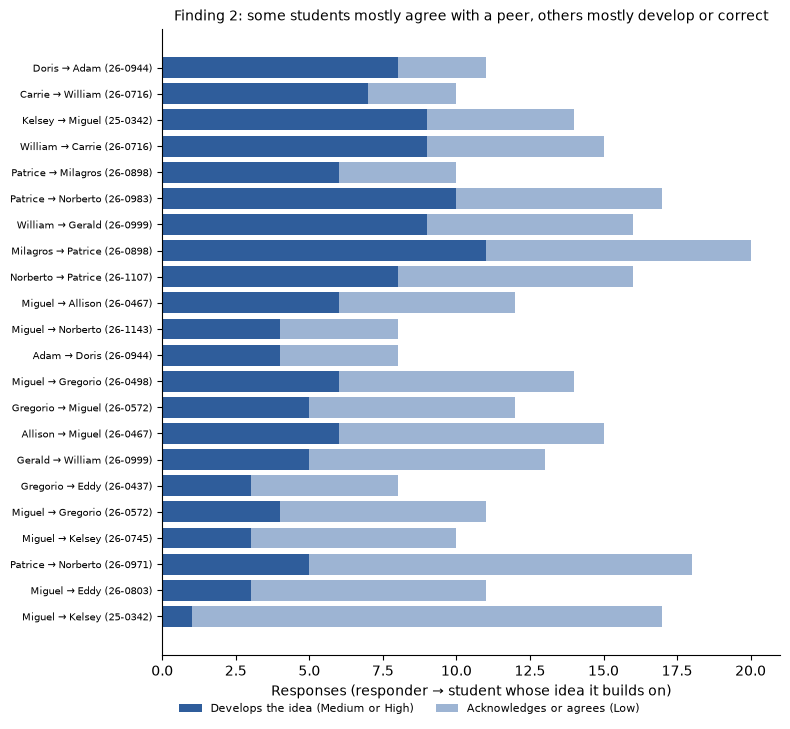

observation responder   source  responses  developed  developed_share
OBS_25-0342    Miguel   Kelsey         17          1             0.06
OBS_26-0803    Miguel     Eddy         11          3             0.27
OBS_26-0971   Patrice Norberto         18          5             0.28
OBS_26-0745    Miguel   Kelsey         10          3             0.30
OBS_26-0572    Miguel Gregorio         11          4             0.36
OBS_26-0437  Gregorio     Eddy          8          3             0.38
OBS_26-0999    Gerald  William         13          5             0.38
OBS_26-0467   Allison   Miguel         15          6             0.40
OBS_26-0572  Gregorio   Miguel         12          5             0.42
OBS_26-0498    Miguel Gregorio         14          6             0.43
OBS_26-0944      Adam    Doris          8          4             0.50
OBS_26-1143    Miguel Norberto          8          4             0.50
OBS_26-0467    Miguel  Allison         12          6             0.50
OBS_26-1107  Norbert

In [14]:
MIN_RESPONSES = 8
directions = (responses.groupby(["observation", "responder", "source"])
              .agg(responses=("developed", "size"), developed=("developed", "sum")).reset_index())
directions["acknowledged"] = directions["responses"] - directions["developed"]
directions["developed_share"] = directions["developed"] / directions["responses"]
directions.to_csv(OUTPUT_DIR / "findings_response_roles.csv", index=False)
shown = directions[directions["responses"] >= MIN_RESPONSES].sort_values("developed_share")
labels = [f"{r.responder} → {r.source} ({r.observation.replace('OBS_', '')})" for r in shown.itertuples()]

figure, axis = plt.subplots(figsize=(8, 0.28 * len(shown) + 1.2))
y = np.arange(len(shown))
axis.barh(y, shown["developed"], color=COLORS["developed"], label="Develops the idea (Medium or High)")
axis.barh(y, shown["acknowledged"], left=shown["developed"], color=COLORS["acknowledged"], label="Acknowledges or agrees (Low)")
axis.set_yticks(y)
axis.set_yticklabels(labels, fontsize=7.5)
axis.set_xlabel("Responses (responder → student whose idea it builds on)")
axis.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.06), ncol=2)
axis.spines[["top", "right"]].set_visible(False)
axis.set_title("Finding 2: some students mostly agree with a peer, others mostly develop or correct", fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "finding2_response_roles.png", dpi=200, bbox_inches="tight")
plt.show()
print(shown[["observation", "responder", "source", "responses", "developed", "developed_share"]].round(2).to_string(index=False))

**What we see.** Students take up a peer's idea in different ways, and the same pair can be lopsided. Among the 22 response directions with at least eight responses, the share that develops the peer's idea ranges from 6% (Miguel responding to Kelsey in OBS_25-0342) to 73% (Doris responding to Adam in OBS_26-0944). In OBS_25-0342 the two directions are nearly opposite: Kelsey develops Miguel's ideas in 9 of her 14 responses, while 16 of Miguel's 17 responses to Kelsey acknowledge or agree. Reading the exchange (rows a23–a30 and a50–a57) shows that Kelsey's developed responses mostly correct Miguel's counts, and Miguel accepts the corrections. The counts place Miguel's ideas among the most developed in the dataset; the exchange shows Kelsey in the role of checker. A code of Medium or High tells us that a student engaged with the details of a peer's idea, not whether they extended it or corrected it.

### Finding 3: Offering more ideas does not mean having more ideas developed

One dot per student per observation, for groups with at least five developed responses. The x-axis is the student's share of the ideas offered in their group (Self turns) and the y-axis is their share of the developed uptake. Dots on the diagonal have their ideas developed in proportion to how many they offer.

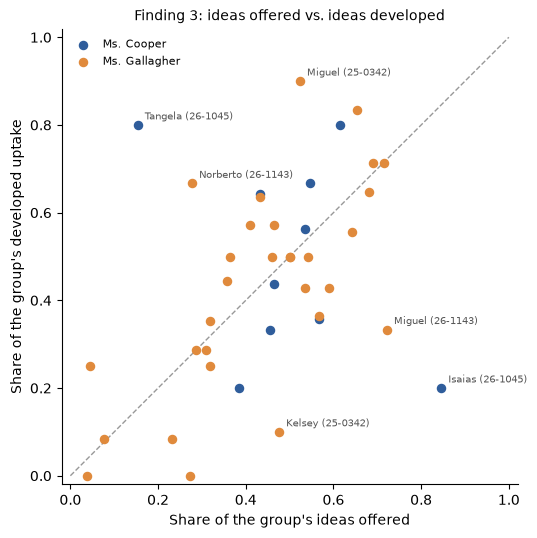

40 student-observations in 18 observations; within 15 points of the diagonal: 23; more than 25 points off: 7
observation  speaker  ideas  developed  idea_share  uptake_share
OBS_26-1045  Tangela      2        4.0        0.15          0.80
OBS_26-1045   Isaias     11        1.0        0.85          0.20
OBS_26-1143   Miguel     13        2.0        0.72          0.33
OBS_26-1143 Norberto      5        4.0        0.28          0.67
OBS_25-0342   Miguel     11        9.0        0.52          0.90
OBS_25-0342   Kelsey     10        1.0        0.48          0.10
OBS_26-0905 Gregorio     12        0.0        0.27          0.00
OBS_26-0999   Gerald     13        9.0        0.43          0.64


In [15]:
MIN_DEVELOPED = 5
shares = uptake[uptake.groupby("observation")["developed"].transform("sum") >= MIN_DEVELOPED].copy()
shares["idea_share"] = shares["ideas"] / shares.groupby("observation")["ideas"].transform("sum")
shares["uptake_share"] = shares["developed"] / shares.groupby("observation")["developed"].transform("sum")
shares["gap"] = shares["uptake_share"] - shares["idea_share"]
shares.to_csv(OUTPUT_DIR / "findings_ideas_vs_uptake.csv", index=False)

figure, axis = plt.subplots(figsize=(5.5, 5.5))
axis.plot([0, 1], [0, 1], color="#999999", linestyle="--", linewidth=1, zorder=1)
for classroom in CLASSROOMS:
    rows = shares[shares["classroom"] == classroom]
    axis.scatter(rows["idea_share"], rows["uptake_share"], s=34, color=CLASSROOM_COLORS[classroom], label=classroom, zorder=3)
for _, row in shares.reindex(shares["gap"].abs().sort_values(ascending=False).index).head(6).iterrows():
    axis.annotate(f"{row['speaker']} ({row['observation'].replace('OBS_', '')})", (row["idea_share"], row["uptake_share"]),
                  textcoords="offset points", xytext=(5, 4), fontsize=7, color="#555555")
axis.set_xlim(-0.02, 1.02)
axis.set_ylim(-0.02, 1.02)
axis.set_aspect("equal")
axis.set_xlabel("Share of the group's ideas offered")
axis.set_ylabel("Share of the group's developed uptake")
axis.legend(frameon=False, fontsize=8, loc="upper left")
axis.spines[["top", "right"]].set_visible(False)
axis.set_title("Finding 3: ideas offered vs. ideas developed", fontsize=10)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "finding3_ideas_vs_uptake.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"{len(shares)} student-observations in {shares['observation'].nunique()} observations; "
      f"within 15 points of the diagonal: {(shares['gap'].abs() <= 0.15).sum()}; more than 25 points off: {(shares['gap'].abs() > 0.25).sum()}")
print(shares.reindex(shares["gap"].abs().sort_values(ascending=False).index).head(8)[
    ["observation", "speaker", "ideas", "developed", "idea_share", "uptake_share"]].round(2).to_string(index=False))

**What we see.** Offering more ideas does not mean having more ideas developed. Of the 40 students in the 18 observations with at least five developed responses, 23 receive a share of the developed uptake within 15 percentage points of their share of the ideas offered, and 7 are more than 25 points away. In the largest gaps, the student who offers fewer ideas receives most of the development: in OBS_26-1045, Tangela offers 15% of the group's ideas and receives 80% of the developed uptake, while Isaias offers 85% and receives 20%; in OBS_26-1143, Norberto offers 28% and receives 67%, while Miguel offers 72% and receives 33%. Counting only who talks, or who offers ideas, would miss whose ideas the group actually develops. These gaps rest on small numbers (four or five developed responses in OBS_26-1045 and OBS_26-1143), so we treat them as cases to read rather than rates to compare.

**Caveats for all three findings.** These are patterns in the enhanced LLM's codes, which have not yet been checked by a human beyond the A4 comparison. Developed responses are rare within one discussion (a median of about 10 per observation), so small differences between students or pairs can arise by chance. Partners and lessons change across observations, which is what Finding 1 describes but also means a student's rate mixes the effects of partner and task.

## Outputs

All files are in `results/uptake_participation/` and contain codes, counts, and scores only, no transcript text.

| File | Contents |
|---|---|
| `turns.csv` | Every student turn with its classroom, Whose, Level, language, and whether a peer took it up |
| `uptake_events.csv` | Every uptake event: source, responder, Level, and the languages of both turns |
| `builds_on_parse_log.csv` | `builds_on` values that named no row, named a different speaker than the transcript, or cited the responder's own line |
| `students.csv` | Per-observation counts and shares for each named student |
| `students_by_classroom.csv`, `uptake_by_student.png`, `uptake_by_student_bars.png` | Whose ideas are taken up, summed by classroom |
| `uptake_matrix.csv`, `uptake_matrix.png` | Who builds on whom |
| `gini.csv`, `gini.png`, `participation_gini.png` | How participation is distributed within each observation |
| `language_uptake.csv`, `language_uptake.png`, `language_uptake_bars.png`, `language_pairs.csv` | Uptake by language, by classroom |
| `gca_comparison.csv`, `gca_comparison.png`, `gca_correlations.csv`, `gca_correlations.png` | LLM-coded uptake against GCA |